<a href="https://colab.research.google.com/github/rahmanziaur/ML-Tute/blob/main/rice_disease_rf_gui.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🌾 Rice Leaf Disease Detector — Random Forest + GUI

This notebook:
1. Loads the **Rice Leaf Disease** dataset (`Rice_Leaf_AUG/<class_name>/*.jpg`)
2. Extracts hand-crafted image features (color, texture, shape) — Random Forest needs engineered features, not raw pixels
3. Trains a `RandomForestClassifier` to classify 6 classes: Healthy, Bacterial Leaf Blight, Brown Spot, Leaf Blast, Leaf scald, Sheath Blight
4. Evaluates the model (accuracy, confusion matrix, feature importance)
5. Launches a simple **Gradio GUI** where a farmer can upload/take a photo of a rice leaf and get an instant diagnosis + advice

Run the cells top to bottom. Runtime: **Runtime → Change runtime type → CPU is fine** (no GPU needed for Random Forest).


## 1. Install dependencies

In [ ]:
!pip install -q opencv-python-headless scikit-image scikit-learn joblib gradio kagglehub


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("anshulm257/rice-disease-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'rice-disease-dataset' dataset.
Path to dataset files: /kaggle/input/rice-disease-dataset


## 2. Get the dataset

If you're loading this from Kaggle (as in your setup, with the "Using Colab cache" message), `kagglehub` will download/cache the dataset automatically. If you already have it mounted at `/kaggle/input/rice-disease-dataset`, that path will be used automatically too — no changes needed.

If you're using a different source (e.g. your own Google Drive), just set `DATASET_DIR` in the next cell to point at the folder that directly contains the 6 class sub-folders (`Leaf scald/`, `Sheath Blight/`, `Healthy Rice Leaf/`, `Leaf Blast/`, `Brown Spot/`, `Bacterial Leaf Blight/`).


In [ ]:
import os

DATASET_DIR = "/kaggle/input/rice-disease-dataset"

if not os.path.isdir(DATASET_DIR):
    print("Local Kaggle path not found — downloading via kagglehub instead...")
    import kagglehub
    # Replace 'owner/rice-disease-dataset' with the exact dataset slug from its Kaggle URL if this differs
    path = kagglehub.dataset_download("owner/rice-disease-dataset")
    print("Downloaded to:", path)
    # Try to auto-locate the Rice_Leaf_AUG folder inside the download
    for root, dirs, files in os.walk(path):
        if "Rice_Leaf_AUG" in dirs:
            DATASET_DIR = os.path.join(root, "Rice_Leaf_AUG")
            break
    else:
        DATASET_DIR = path  # fallback: use whatever kagglehub returned

print("Using DATASET_DIR:", DATASET_DIR)
print("Classes found:", sorted(os.listdir(DATASET_DIR)))


Using DATASET_DIR: /kaggle/input/rice-disease-dataset
Classes found: ['Rice_Leaf_AUG']


## 3. Feature extraction

Random Forest can't learn from raw pixels the way a CNN does, so each leaf image is converted into a compact **51-value feature vector**:

- Color statistics (RGB + HSV mean/std) — 12 features
- Color histograms (HSV, 8 bins/channel) — 24 features
- GLCM texture (contrast, homogeneity, energy, correlation, dissimilarity, ASM) — 6 features
- Edge density (Canny) — 1 feature
- Hu moments (shape of dark lesion regions) — 7 features
- Lesion/spot color ratio (brown/yellow spot heuristic) — 1 feature

This same function is reused later by the GUI, so training and inference always match.


In [ ]:
import cv2
import numpy as np
from skimage.feature import graycomatrix, graycoprops

IMG_SIZE = 128  # all images resized to this before feature extraction


def _color_stats(img_rgb, img_hsv):
    feats = []
    for img in (img_rgb, img_hsv):
        for c in range(3):
            channel = img[:, :, c]
            feats.append(channel.mean())
            feats.append(channel.std())
    return feats  # 12 values


def _color_histogram(img_hsv, bins=8):
    feats = []
    for c in range(3):
        hist = cv2.calcHist([img_hsv], [c], None, [bins], [0, 256])
        hist = cv2.normalize(hist, hist).flatten()
        feats.extend(hist.tolist())
    return feats  # 24 values


def _glcm_features(gray):
    gray_q = (gray / 32).astype(np.uint8)  # reduce to 8 gray levels for a stable, fast GLCM
    glcm = graycomatrix(
        gray_q, distances=[1], angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
        levels=8, symmetric=True, normed=True
    )
    props = ["contrast", "homogeneity", "energy", "correlation", "dissimilarity", "ASM"]
    return [graycoprops(glcm, p).mean() for p in props]  # 6 values


def _edge_density(gray):
    edges = cv2.Canny(gray, 100, 200)
    return [float(np.mean(edges > 0))]  # 1 value


def _hu_moments(gray):
    _, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    moments = cv2.moments(thresh)
    hu = cv2.HuMoments(moments).flatten()
    hu = -np.sign(hu) * np.log10(np.abs(hu) + 1e-30)  # log-scale for numerical stability
    return hu.tolist()  # 7 values


def _lesion_ratio(img_hsv):
    lower = np.array([5, 40, 20])
    upper = np.array([35, 255, 200])
    mask = cv2.inRange(img_hsv, lower, upper)
    return [float(np.mean(mask > 0))]  # 1 value


def extract_features(image_bgr_or_rgb, is_bgr=True):
    """Take a single image (cv2.imread -> BGR, or a numpy RGB array from Gradio/PIL)
    and return a 1D numpy feature vector."""
    img = image_bgr_or_rgb
    if img is None:
        raise ValueError("Empty image passed to extract_features")
    if not is_bgr:
        img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)

    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    feats = []
    feats += _color_stats(img_rgb, img_hsv)
    feats += _color_histogram(img_hsv)
    feats += _glcm_features(gray)
    feats += _edge_density(gray)
    feats += _hu_moments(gray)
    feats += _lesion_ratio(img_hsv)
    return np.array(feats, dtype=np.float32)


FEATURE_LENGTH = len(extract_features(np.zeros((IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8), is_bgr=True))
print("Feature vector length:", FEATURE_LENGTH)


Feature vector length: 51


In [ ]:
import os
print(os.listdir(DATASET_DIR))

['Rice_Leaf_AUG']


In [ ]:
DATASET_DIR = os.path.join(DATASET_DIR, "Rice_Leaf_AUG")
print(os.listdir(DATASET_DIR))

['Leaf scald', 'Sheath Blight', 'Healthy Rice Leaf', 'Leaf Blast', 'Brown Spot', 'Bacterial Leaf Blight']


In [ ]:
if not os.path.isdir(DATASET_DIR):
    ...
    path = kagglehub.dataset_download("owner/rice-disease-dataset")
    for root, dirs, files in os.walk(path):
        if "Rice_Leaf_AUG" in dirs:
            DATASET_DIR = os.path.join(root, "Rice_Leaf_AUG")
            break
    else:
        DATASET_DIR = path  # <-- this fallback triggered

## 4. Load dataset & extract features

This walks every class folder and builds the feature matrix `X` and labels `y`. For a quick first run on a large dataset, you can cap images per class with `MAX_IMAGES_PER_CLASS` below (set to `None` to use everything).


In [ ]:
import glob

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")
MAX_IMAGES_PER_CLASS = None  # e.g. 800 for a faster first run, None = use all images

def load_dataset(dataset_dir):
    class_names = sorted(
        d for d in os.listdir(dataset_dir)
        if os.path.isdir(os.path.join(dataset_dir, d))
    )
    if not class_names:
        raise RuntimeError(f"No class sub-folders found in {dataset_dir}")
    print(f"Found {len(class_names)} classes: {class_names}")

    X, y = [], []
    for class_name in class_names:
        class_dir = os.path.join(dataset_dir, class_name)
        paths = []
        for ext in IMAGE_EXTENSIONS:
            paths += glob.glob(os.path.join(class_dir, f"*{ext}"))
            paths += glob.glob(os.path.join(class_dir, f"*{ext.upper()}"))
        paths = sorted(set(paths))
        if MAX_IMAGES_PER_CLASS:
            paths = paths[:MAX_IMAGES_PER_CLASS]

        print(f"  {class_name}: {len(paths)} images")
        ok, bad = 0, 0
        for p in paths:
            img = cv2.imread(p)
            if img is None:
                bad += 1
                continue
            try:
                feats = extract_features(img, is_bgr=True)
            except Exception:
                bad += 1
                continue
            X.append(feats)
            y.append(class_name)
            ok += 1
        if bad:
            print(f"    (skipped {bad} unreadable/corrupt files)")
    return np.array(X, dtype=np.float32), np.array(y)


print("Loading dataset and extracting features (this can take a while)...")
X, y = load_dataset(DATASET_DIR)
print(f"\nTotal samples: {X.shape[0]}, feature dimension: {X.shape[1]}")


Loading dataset and extracting features (this can take a while)...
Found 6 classes: ['Bacterial Leaf Blight', 'Brown Spot', 'Healthy Rice Leaf', 'Leaf Blast', 'Leaf scald', 'Sheath Blight']
  Bacterial Leaf Blight: 636 images
  Brown Spot: 646 images
  Healthy Rice Leaf: 653 images
  Leaf Blast: 634 images
  Leaf scald: 628 images
  Sheath Blight: 632 images

Total samples: 3829, feature dimension: 51


## 5. Train the Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

le = LabelEncoder()
y_enc = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, random_state=42, stratify=y_enc
)

clf = RandomForestClassifier(
    n_estimators=400,
    max_depth=None,
    min_samples_leaf=2,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42,
)
clf.fit(X_train, y_train)

cv_scores = cross_val_score(clf, X_train, y_train, cv=5, n_jobs=-1)
print(f"5-fold CV accuracy: {cv_scores.mean():.3f} +/- {cv_scores.std():.3f}")

y_pred = clf.predict(X_test)
print("\nTest set performance:")
print(classification_report(y_test, y_pred, target_names=le.classes_))


5-fold CV accuracy: 0.889 +/- 0.011

Test set performance:
                       precision    recall  f1-score   support

Bacterial Leaf Blight       0.93      0.88      0.90       127
           Brown Spot       0.95      0.91      0.93       129
    Healthy Rice Leaf       0.93      0.97      0.95       131
           Leaf Blast       0.84      0.87      0.85       127
           Leaf scald       0.88      0.91      0.90       126
        Sheath Blight       0.93      0.91      0.92       126

             accuracy                           0.91       766
            macro avg       0.91      0.91      0.91       766
         weighted avg       0.91      0.91      0.91       766



### Confusion matrix & feature importance

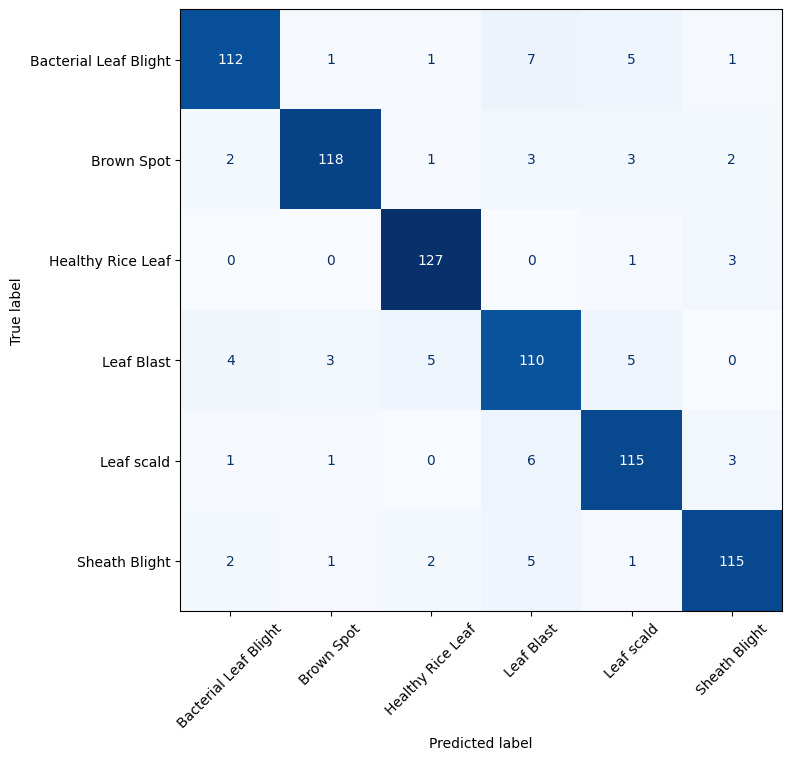

In [ ]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
plt.tight_layout()
plt.show()


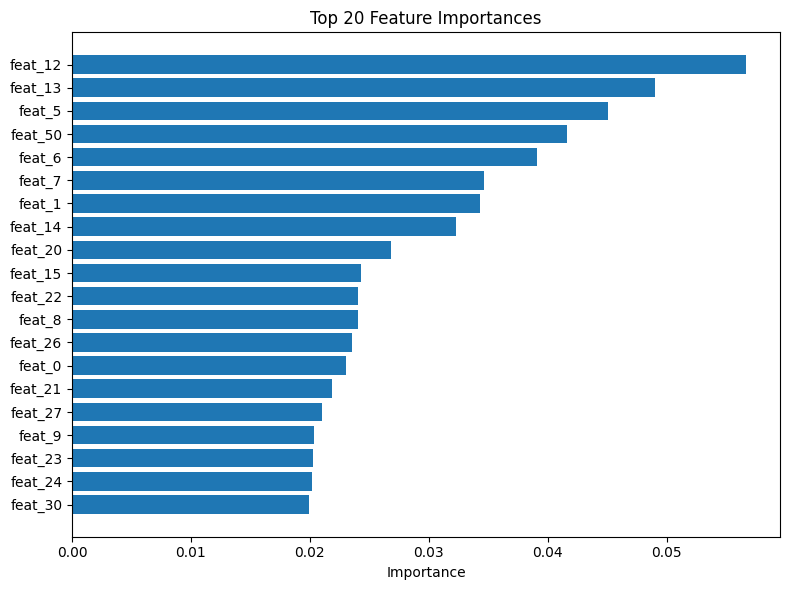

In [ ]:
importances = clf.feature_importances_
order = np.argsort(importances)[::-1][:20]
plt.figure(figsize=(8, 6))
plt.barh(range(len(order)), importances[order][::-1])
plt.yticks(range(len(order)), [f"feat_{i}" for i in order][::-1])
plt.xlabel("Importance")
plt.title("Top 20 Feature Importances")
plt.tight_layout()
plt.show()


## 6. Save the model

In [ ]:
import joblib

OUTPUT_DIR = "/content/rice_model"
os.makedirs(OUTPUT_DIR, exist_ok=True)

joblib.dump(clf, os.path.join(OUTPUT_DIR, "rice_rf_model.joblib"))
joblib.dump(le, os.path.join(OUTPUT_DIR, "label_encoder.joblib"))
print("Saved to:", OUTPUT_DIR)


Saved to: /content/rice_model


## 7. GUI for farmers

A simple Gradio app: upload or take a photo of a rice leaf → get the predicted disease (English + Bangla), a confidence score, top-3 possibilities, and short practical advice.

Edit the `DISEASE_INFO` dictionary below to match your local agronomic recommendations — the text provided is generic starting-point guidance, not authoritative advice.


In [ ]:
import gradio as gr

DISEASE_INFO = {
    "Healthy Rice Leaf": {
        "bangla": "সুস্থ ধান পাতা",
        "advice": "Leaf looks healthy. No treatment needed — keep monitoring the field weekly.",
    },
    "Bacterial Leaf Blight": {
        "bangla": "ব্যাকটেরিয়াল লিফ ব্লাইট",
        "advice": "Drain excess standing water, avoid excess nitrogen fertilizer, and remove/burn "
                   "severely infected leaves. Consult your local agricultural office about approved "
                   "bactericides (e.g. copper-based sprays) for your region.",
    },
    "Brown Spot": {
        "bangla": "ব্রাউন স্পট (বাদামী দাগ রোগ)",
        "advice": "Often linked to potassium/nutrient deficiency or seed-borne infection. Balance "
                   "fertilizer (esp. potassium), use certified disease-free seed next season, and "
                   "consult local extension services about a suitable fungicide if severe.",
    },
    "Leaf Blast": {
        "bangla": "লিফ ব্লাস্ট",
        "advice": "Avoid excess nitrogen, ensure good field drainage, and consult local agricultural "
                   "office promptly about approved fungicides — blast can spread fast in humid weather.",
    },
    "Leaf scald": {
        "bangla": "লিফ স্ক্যাল্ড",
        "advice": "Common in dense, over-fertilized crops. Improve field spacing/airflow, avoid excess "
                   "nitrogen, and remove badly affected leaves.",
    },
    "Sheath Blight": {
        "bangla": "শীথ ব্লাইট",
        "advice": "Reduce plant density, avoid excess nitrogen, improve drainage, and consult local "
                   "extension office about approved fungicides if spreading in the field.",
    },
}
DEFAULT_ADVICE = "Consult your local agricultural extension office for a confirmed diagnosis and treatment."


def diagnose(image):
    if image is None:
        return "Please upload a photo of a rice leaf.", "", {}

    feats = extract_features(np.array(image), is_bgr=False).reshape(1, -1)
    proba = clf.predict_proba(feats)[0]
    order = np.argsort(proba)[::-1]
    top_idx = order[0]
    disease = le.classes_[top_idx]
    confidence = proba[top_idx]

    info = DISEASE_INFO.get(disease, {})
    bangla = info.get("bangla", "")
    advice = info.get("advice", DEFAULT_ADVICE)

    headline = f"🌾 {disease}" + (f"  ({bangla})" if bangla else "")
    headline += f"\nConfidence: {confidence * 100:.1f}%"

    top3 = {le.classes_[i]: float(proba[i]) for i in order[:3]}
    return headline, advice, top3


with gr.Blocks(title="Rice Leaf Disease Detector") as demo:
    gr.Markdown(
        "# 🌾 Rice Leaf Disease Detector\n"
        "Upload or take a photo of a rice leaf to check for common diseases. "
        "ধানের পাতার ছবি তুলুন বা আপলোড করুন — রোগ শনাক্ত করতে সাহায্য করবে।"
    )
    with gr.Row():
        with gr.Column():
            image_input = gr.Image(type="numpy", label="Rice Leaf Photo / ধানের পাতার ছবি", sources=["upload", "webcam"])
            btn = gr.Button("🔍 Diagnose / নির্ণয় করুন", variant="primary")
        with gr.Column():
            result_label = gr.Textbox(label="Diagnosis / রোগ নির্ণয়", lines=3)
            advice_box = gr.Textbox(label="Advice / পরামর্শ", lines=4)
            top3_label = gr.Label(label="Top 3 possibilities / সম্ভাব্য রোগসমূহ")

    btn.click(fn=diagnose, inputs=image_input, outputs=[result_label, advice_box, top3_label])
    image_input.change(fn=diagnose, inputs=image_input, outputs=[result_label, advice_box, top3_label])

    gr.Markdown(
        "_Disclaimer: This is an AI-assisted tool and not a substitute for expert agronomic advice. "
        "For severe or spreading infections, please contact your local agricultural extension office._"
    )


Run the cell below to launch the GUI. It prints a public link (valid ~72h) you can open on your phone or share with a farmer directly.

In [ ]:
demo.launch(share=True, debug=False)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://66971129a752565274.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
